## Lab 1 - Intro to Behavioral TV Data
# Name: Mykhailo Vasyliev
# Group: КМ-41

### Setup

In [1]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


### Helper Functions

In [2]:
def get_person_weights(daily_weights):
    """
    Calculates the average monthly weight for each person (types R, L).
    """
    persons_dw = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])]
    return persons_dw.groupby('respondent_id')['weight'].mean().reset_index()

def prepare_viewings(viewings, programs, viewer_attributes):
    """
    Merges viewings with program information and viewer demographics.

    Filters for persons only (excludes H and S).
    Calculates the duration of each session in minutes and counts views longer than one minute.
    """
    v_persons = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()

    v_persons['duration_min'] = (v_persons['end_ts'] - v_persons['start_ts']).dt.total_seconds() / 60.0
    v_persons = v_persons[v_persons['duration_min'] >= 1.0]

    return v_persons

### Task 1.1 - Panel and universe

In [3]:
telecasts_count = programs['telecast_id'].nunique()
programs_count = programs['program_name'].nunique()
networks_count = programs['network_code'].nunique()

hh_in_tab_total = daily_weights[daily_weights['resp_type'] == 'H']['respondent_id'].nunique()
persons_in_tab_total = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])]['respondent_id'].nunique()

daily_stats = daily_weights.groupby(['broadcast_date', 'resp_type'])['weight'].agg(['count', 'sum']).reset_index()

avg_hh_in_tab = daily_stats[daily_stats['resp_type'] == 'H']['count'].mean()
avg_persons_in_tab = daily_stats[daily_stats['resp_type'].isin(['R', 'L'])]['count'].mean()

avg_hh_universe_m = daily_stats[daily_stats['resp_type'] == 'H']['sum'].mean() / 1_000_000
avg_persons_universe_m = daily_stats[daily_stats['resp_type'].isin(['R', 'L'])]['sum'].mean() / 1_000_000

print("Telecasts:", telecasts_count)
print("Programs:", programs_count)
print("Networks:", networks_count)
print("Households in panel:", hh_in_tab_total)
print("Persons in panel:", persons_in_tab_total)
print(f"Households in-tab, average day: {avg_hh_in_tab:.0f}")
print(f"Persons in-tab, average day: {avg_persons_in_tab:.0f}")
print(f"US TV households represented, average day (M): {avg_hh_universe_m:.2f}")
print(f"US persons represented, average day (M): {avg_persons_universe_m:.2f}")

Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878
Persons in-tab, average day: 4634
US TV households represented, average day (M): 125.80
US persons represented, average day (M): 158.64


### Task 1.2 - Average audience by hour of day

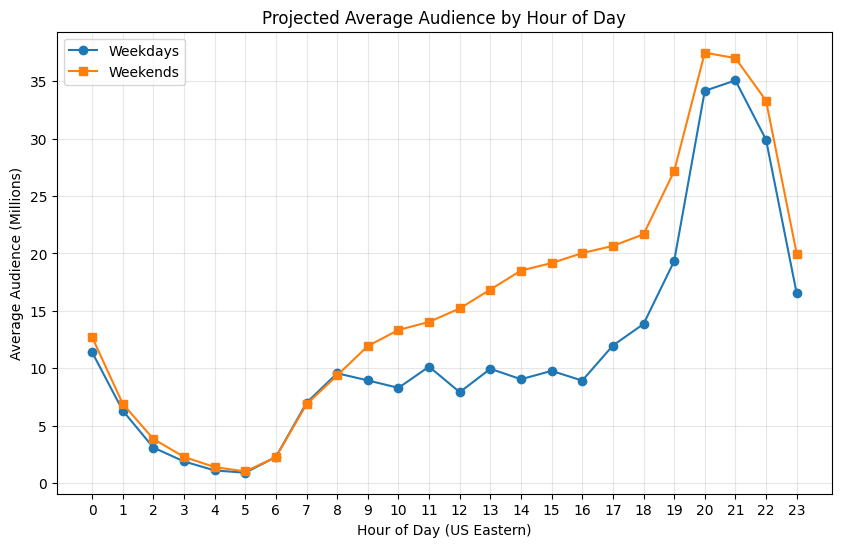

Peak hour, weekdays: 21
Peak hour, weekends: 20


In [4]:
v_persons = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()

def split_viewing_by_hour(df):
    records = []
    for _, row in df.iterrows():
        start = row['start_ts']
        end = row['end_ts']
        weight = row['weight']

        current_time = start
        while current_time < end:
            next_hour = (current_time + pd.Timedelta(hours=1)).replace(minute=0, second=0, microsecond=0)
            chunk_end = min(end, next_hour)
            duration_mins = (chunk_end - current_time).total_seconds() / 60.0

            hour_of_day = current_time.hour
            broadcast_date = current_time.date()
            if hour_of_day < 6:
                broadcast_date -= pd.Timedelta(days=1)

            is_weekend = broadcast_date.weekday() >= 5

            records.append({
                'hour': hour_of_day,
                'is_weekend': is_weekend,
                'weighted_minutes': duration_mins * weight
            })
            current_time = chunk_end
    return pd.DataFrame(records)

hourly_viewing = split_viewing_by_hour(v_persons)

oct_dates = daily_weights['broadcast_date'].unique()
num_weekdays = sum([1 for d in oct_dates if d.weekday() < 5])
num_weekends = sum([1 for d in oct_dates if d.weekday() >= 5])

hourly_summary = hourly_viewing.groupby(['hour', 'is_weekend'])['weighted_minutes'].sum().reset_index()

hourly_summary.loc[hourly_summary['is_weekend'] == False, 'avg_audience_m'] = \
    (hourly_summary['weighted_minutes'] / 60 / num_weekdays) / 1_000_000

hourly_summary.loc[hourly_summary['is_weekend'] == True, 'avg_audience_m'] = \
    (hourly_summary['weighted_minutes'] / 60 / num_weekends) / 1_000_000

weekdays_data = hourly_summary[hourly_summary['is_weekend'] == False].sort_values('hour')
weekends_data = hourly_summary[hourly_summary['is_weekend'] == True].sort_values('hour')

plt.figure(figsize=(10, 6))
plt.plot(weekdays_data['hour'], weekdays_data['avg_audience_m'], label='Weekdays', marker='o')
plt.plot(weekends_data['hour'], weekends_data['avg_audience_m'], label='Weekends', marker='s')
plt.title('Projected Average Audience by Hour of Day')
plt.xlabel('Hour of Day (US Eastern)')
plt.ylabel('Average Audience (Millions)')
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

peak_weekday = weekdays_data.loc[weekdays_data['avg_audience_m'].idxmax(), 'hour']
peak_weekend = weekends_data.loc[weekends_data['avg_audience_m'].idxmax(), 'hour']

print(f"Peak hour, weekdays: {peak_weekday}")
print(f"Peak hour, weekends: {peak_weekend}")

# **Answer:** During weekends, TV viewership is notably higher throughout the daytime and builds steadily from the morning hours. In contrast, weekday viewing remains consistently lower and flat during the day, followed by a sharp spike in the evening, reaching its peak at hour 21.

### Task 1.3 - Session length

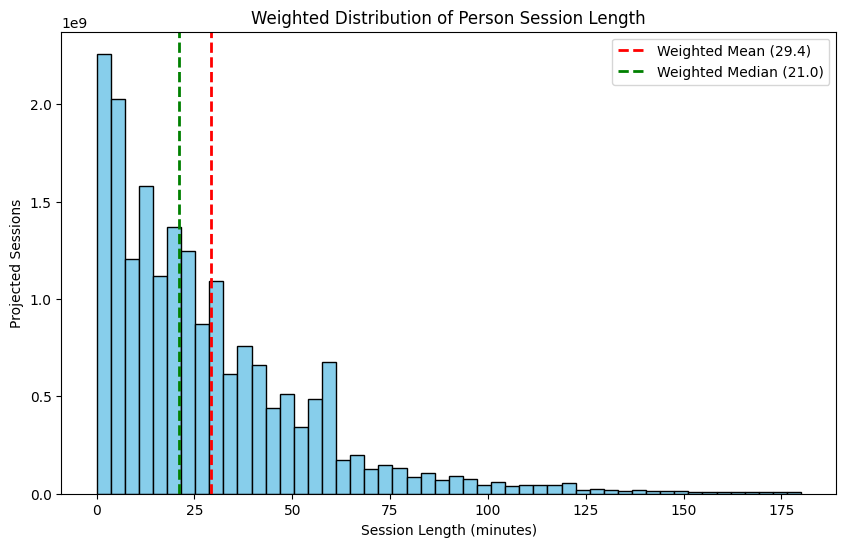

Session length, weighted mean (min): 29.4
Session length, weighted median (min): 21.0


In [5]:
v_persons['duration_min'] = (v_persons['end_ts'] - v_persons['start_ts']).dt.total_seconds() / 60.0

weighted_mean = np.average(v_persons['duration_min'], weights=v_persons['weight'])

def weighted_median(data, weights):
    sorted_indices = np.argsort(data)
    sorted_data = data.iloc[sorted_indices]
    sorted_weights = weights.iloc[sorted_indices]
    cumulative_weights = np.cumsum(sorted_weights)
    cutoff = cumulative_weights.iloc[-1] / 2.0
    return sorted_data[cumulative_weights >= cutoff].iloc[0]

w_median = weighted_median(v_persons['duration_min'], v_persons['weight'])

plt.figure(figsize=(10, 6))
plt.hist(v_persons['duration_min'], weights=v_persons['weight'], bins=50, range=(0, 180), color='skyblue', edgecolor='black')
plt.axvline(weighted_mean, color='red', linestyle='dashed', linewidth=2, label=f'Weighted Mean ({weighted_mean:.1f})')
plt.axvline(w_median, color='green', linestyle='dashed', linewidth=2, label=f'Weighted Median ({w_median:.1f})')
plt.title('Weighted Distribution of Person Session Length')
plt.xlabel('Session Length (minutes)')
plt.ylabel('Projected Sessions')
plt.legend()
plt.show()

print(f"Session length, weighted mean (min): {weighted_mean:.1f}")
print(f"Session length, weighted median (min): {w_median:.1f}")

# **Answer:** The mean (29.4 minutes) is noticeably higher than the median (21.0 minutes) because the distribution of session lengths is heavily right-skewed. This means that while most sessions are short, a small number of very long viewing sessions significantly inflate the average. It would be more appropriate to show the client the median, as it more accurately reflects 'typical' viewer behavior and is not skewed by extreme outliers.

### Task 2 - Program reach curve

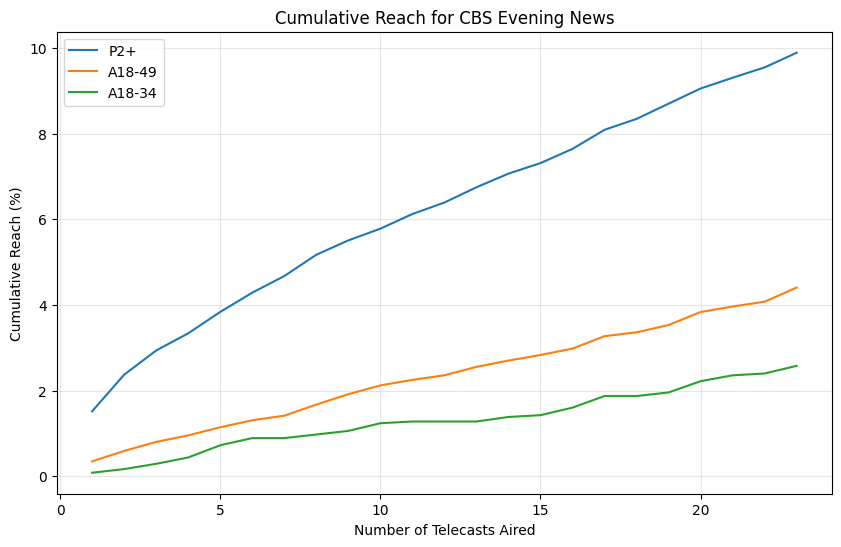

Telecasts of the program: 23
Average household rating (%): 3.2
Average P2+ rating (%): 172.2
Average projected audience (M): 4.93
Final reach P2+ (%): 9.9
Final reach A18-34 (%): 2.6
Final reach A18-49 (%): 4.4


In [6]:
cbs_news = programs[
    (programs['program_name'] == 'CBS Evening News') &
    (programs['network_code'] == 'CBS')
].copy()
cbs_news['day_of_week'] = pd.to_datetime(cbs_news['broadcast_date']).dt.weekday
cbs_news = cbs_news[cbs_news['day_of_week'] < 5].sort_values('start_ts')

ages = viewer_attributes[(viewer_attributes['attr_id'] == 300) & (viewer_attributes['respondent_id'] % 100 != 0)][['respondent_id', 'value']]
ages.columns = ['respondent_id', 'age']

results = []
reach_sets = {
    'P2+': set(),
    'A18_34': set(),
    'A18_49': set()
}

monthly_weights = get_person_weights(daily_weights)

daily_universe = daily_weights.groupby(['broadcast_date', 'resp_type'])['weight'].sum().reset_index()

for _, telecast in cbs_news.iterrows():
    t_start = telecast['start_ts']
    t_end = telecast['end_ts']
    b_date = telecast['broadcast_date']
    t_id = telecast['telecast_id']

    overlapping = viewings[
        (viewings['network_code'] == telecast['network_code']) &
        (viewings['start_ts'] < t_end) &
        (viewings['end_ts'] > t_start) &
        (viewings['resp_type'].isin(['H', 'R', 'L']))
    ].copy()

    overlapping['overlap_start'] = overlapping['start_ts'].clip(lower=t_start)
    overlapping['overlap_end'] = overlapping['end_ts'].clip(upper=t_end)
    overlapping['overlap_min'] = (overlapping['overlap_end'] - overlapping['overlap_start']).dt.total_seconds() / 60.0

    viewers = overlapping[overlapping['overlap_min'] >= 1.0].drop_duplicates(subset=['respondent_id'])

    hh_viewers = viewers[viewers['resp_type'] == 'H']
    hh_in_tab = daily_universe[(daily_universe['broadcast_date'] == b_date) & (daily_universe['resp_type'] == 'H')]['weight'].values[0]
    hh_rating = (hh_viewers['weight'].sum() / hh_in_tab) * 100

    p2_viewers = viewers[viewers['resp_type'].isin(['R', 'L'])]
    p2_in_tab = daily_universe[(daily_universe['broadcast_date'] == b_date) & (daily_universe['resp_type'].isin(['R', 'L']))]['weight'].values[0]
    p2_rating = (p2_viewers['weight'].sum() / p2_in_tab) * 100

    proj_audience_m = p2_viewers['weight'].sum() / 1_000_000

    results.append({
        'telecast_id': t_id,
        'date': b_date,
        'hh_rating': hh_rating,
        'p2_rating': p2_rating,
        'proj_audience_m': proj_audience_m
    })

    p2_ids = p2_viewers['respondent_id'].tolist()
    reach_sets['P2+'].update(p2_ids)

    p2_with_age = p2_viewers.merge(ages, on='respondent_id', how='inner')
    reach_sets['A18_34'].update(p2_with_age[(p2_with_age['age'] >= 18) & (p2_with_age['age'] <= 34)]['respondent_id'].tolist())
    reach_sets['A18_49'].update(p2_with_age[(p2_with_age['age'] >= 18) & (p2_with_age['age'] <= 49)]['respondent_id'].tolist())

ratings_df = pd.DataFrame(results)

def calc_reach(reached_ids, target_group_ids):
    reached_weights_sum = monthly_weights[monthly_weights['respondent_id'].isin(reached_ids)]['weight'].sum()
    target_weights_sum = monthly_weights[monthly_weights['respondent_id'].isin(target_group_ids)]['weight'].sum()
    return (reached_weights_sum / target_weights_sum) * 100

all_p2_ids = monthly_weights['respondent_id'].tolist()
all_with_age = monthly_weights.merge(ages, on='respondent_id', how='inner')
all_18_34_ids = all_with_age[(all_with_age['age'] >= 18) & (all_with_age['age'] <= 34)]['respondent_id'].tolist()
all_18_49_ids = all_with_age[(all_with_age['age'] >= 18) & (all_with_age['age'] <= 49)]['respondent_id'].tolist()

final_reach_p2 = calc_reach(reach_sets['P2+'], all_p2_ids)
final_reach_18_34 = calc_reach(reach_sets['A18_34'], all_18_34_ids)
final_reach_18_49 = calc_reach(reach_sets['A18_49'], all_18_49_ids)

cum_reach_data = []
current_sets = {'P2+': set(), 'A18_34': set(), 'A18_49': set()}

for i, telecast in cbs_news.iterrows():
    t_start = telecast['start_ts']
    t_end = telecast['end_ts']

    overlapping = viewings[(viewings['network_code'] == telecast['network_code']) & (viewings['start_ts'] < t_end) & (viewings['end_ts'] > t_start) & (viewings['resp_type'].isin(['R', 'L']))].copy()
    overlapping['overlap_min'] = (overlapping['end_ts'].clip(upper=t_end) - overlapping['start_ts'].clip(lower=t_start)).dt.total_seconds() / 60.0
    viewers = overlapping[overlapping['overlap_min'] >= 1.0].merge(ages, on='respondent_id', how='left')

    current_sets['P2+'].update(viewers['respondent_id'].tolist())
    current_sets['A18_34'].update(viewers[(viewers['age'] >= 18) & (viewers['age'] <= 34)]['respondent_id'].tolist())
    current_sets['A18_49'].update(viewers[(viewers['age'] >= 18) & (viewers['age'] <= 49)]['respondent_id'].tolist())

    cum_reach_data.append({
        'telecast_index': len(cum_reach_data) + 1,
        'P2+': calc_reach(current_sets['P2+'], all_p2_ids),
        'A18_34': calc_reach(current_sets['A18_34'], all_18_34_ids),
        'A18_49': calc_reach(current_sets['A18_49'], all_18_49_ids)
    })

cum_reach_df = pd.DataFrame(cum_reach_data)

plt.figure(figsize=(10, 6))
plt.plot(cum_reach_df['telecast_index'], cum_reach_df['P2+'], label='P2+')
plt.plot(cum_reach_df['telecast_index'], cum_reach_df['A18_49'], label='A18-49')
plt.plot(cum_reach_df['telecast_index'], cum_reach_df['A18_34'], label='A18-34')
plt.title('Cumulative Reach for CBS Evening News')
plt.xlabel('Number of Telecasts Aired')
plt.ylabel('Cumulative Reach (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Telecasts of the program: {len(cbs_news)}")
print(f"Average household rating (%): {ratings_df['hh_rating'].mean():.1f}")
print(f"Average P2+ rating (%): {ratings_df['p2_rating'].mean():.1f}")
print(f"Average projected audience (M): {ratings_df['proj_audience_m'].mean():.2f}")
print(f"Final reach P2+ (%): {final_reach_p2:.1f}")
print(f"Final reach A18-34 (%): {final_reach_18_34:.1f}")
print(f"Final reach A18-49 (%): {final_reach_18_49:.1f}")

# **Answer:** Cumulative reach continues to grow steadily with each new telecast because every episode attracts a certain share of new, unique viewers who did not watch previous broadcasts. The graph clearly shows that the program best reaches the broad P2+ audience (with final reach hitting 9.9%), while younger demographic groups are reached significantly less — 4.4% for A18-49 and only 2.6% for A18-34. This perfectly aligns with the typical demographics of evening network news, which traditionally attracts an older audience rather than young adults.

### Task 3 - Program frequency

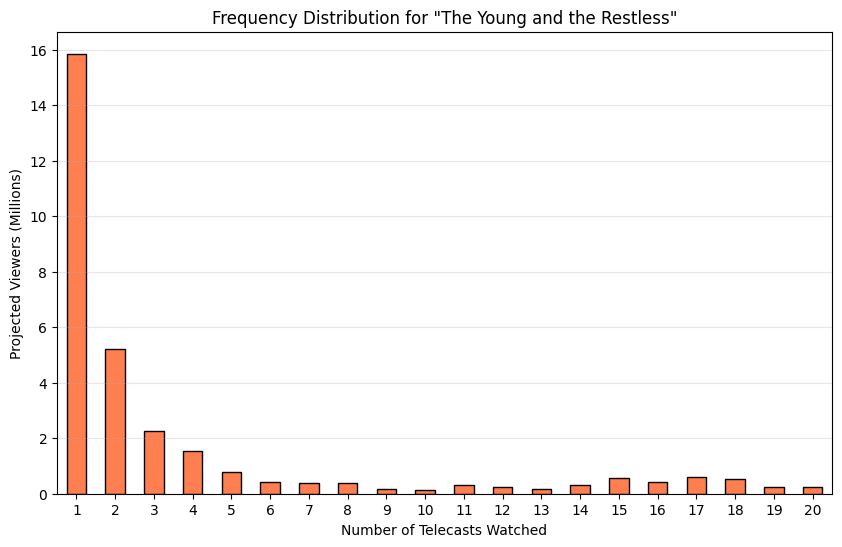

Projected viewers (M): 30.80
Average frequency (weighted): 3.6
Median frequency (weighted): 1.0
Share of views from the most loyal viewers: 0.704


In [7]:
y_and_r = programs[
    (programs['program_name'] == 'The Young and the Restless') &
    (programs['network_code'] == 'CBS')
].copy()

viewer_freq = {}
for _, telecast in y_and_r.iterrows():
    t_start = telecast['start_ts']
    t_end = telecast['end_ts']

    overlapping = viewings[(viewings['network_code'] == telecast['network_code']) & (viewings['start_ts'] < t_end) & (viewings['end_ts'] > t_start) & (viewings['resp_type'].isin(['R', 'L']))].copy()
    overlapping['overlap_min'] = (overlapping['end_ts'].clip(upper=t_end) - overlapping['start_ts'].clip(lower=t_start)).dt.total_seconds() / 60.0
    viewers = overlapping[overlapping['overlap_min'] >= 1.0]['respondent_id'].unique()

    for vid in viewers:
        viewer_freq[vid] = viewer_freq.get(vid, 0) + 1

freq_df = pd.DataFrame(list(viewer_freq.items()), columns=['respondent_id', 'frequency'])
freq_df = freq_df.merge(monthly_weights, on='respondent_id', how='inner')

total_viewers_m = freq_df['weight'].sum() / 1_000_000
avg_freq = np.average(freq_df['frequency'], weights=freq_df['weight'])
median_freq = weighted_median(freq_df['frequency'], freq_df['weight'])

freq_dist = freq_df.groupby('frequency')['weight'].sum() / 1_000_000

plt.figure(figsize=(10, 6))
freq_dist.plot(kind='bar', color='coral', edgecolor='black')
plt.title('Frequency Distribution for "The Young and the Restless"')
plt.xlabel('Number of Telecasts Watched')
plt.ylabel('Projected Viewers (Millions)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.show()

sorted_freq = freq_df.sort_values('frequency')
sorted_freq['cum_weight_pct'] = sorted_freq['weight'].cumsum() / sorted_freq['weight'].sum()
threshold = sorted_freq[sorted_freq['cum_weight_pct'] >= 0.8]['frequency'].iloc[0]

loyal_viewers = freq_df[freq_df['frequency'] >= threshold]
total_views = (freq_df['frequency'] * freq_df['weight']).sum()
loyal_views = (loyal_viewers['frequency'] * loyal_viewers['weight']).sum()
loyal_share = loyal_views / total_views

print(f"Projected viewers (M): {total_viewers_m:.2f}")
print(f"Average frequency (weighted): {avg_freq:.1f}")
print(f"Median frequency (weighted): {median_freq:.1f}")
print(f"Share of views from the most loyal viewers: {loyal_share:.3f}")

# **Answer:** The average frequency (3.6) is not a fair or objective summary for this audience, as the median frequency is only 1.0. The graph illustrates a highly polarized distribution: the vast majority of viewers (nearly 16 million) watched only a single telecast of the program. However, there is a small but highly loyal group of viewers who watch a significant number of broadcasts (the long tail on the graph), and it is this exact group that accounts for the absolute majority — 70.4% of all views. This is a textbook example of how the average can be misleading and misrepresent typical audience behavior due to extreme outliers.

### Task 4 - Networks by age and gender

In [8]:
sex_data = viewer_attributes[viewer_attributes['attr_id'].isin([201, 202])][['respondent_id', 'attr_id']]
sex_data['gender'] = sex_data['attr_id'].map({201: 'M', 202: 'W'})

demo = ages.merge(sex_data[['respondent_id', 'gender']], on='respondent_id', how='inner')

def get_demo_group(row):
    g = row['gender']
    a = row['age']
    if 18 <= a <= 34: return f"{g}18-34"
    elif 35 <= a <= 54: return f"{g}35-54"
    elif a >= 55: return f"{g}55+"
    return "Other"

demo['demo_group'] = demo.apply(get_demo_group, axis=1)

v_demo = v_persons.merge(demo, on='respondent_id', how='inner')
v_demo['proj_minutes'] = v_demo['duration_min'] * v_demo['weight']

target_groups = ['M18-34', 'W18-34', 'M35-54', 'W35-54', 'M55+', 'W55+']

for group in target_groups:
    group_data = v_demo[v_demo['demo_group'] == group]
    top_5 = group_data.groupby('network_code')['proj_minutes'].sum().sort_values(ascending=False).head(5)
    print(f"\nTop 5 for {group} (Projected Minutes):")
    print(top_5)

network_stats = []
networks = v_demo['network_code'].unique()

for net in networks:
    net_data = v_demo[v_demo['network_code'] == net]

    total_proj_min = net_data['proj_minutes'].sum()
    youth_proj_min = net_data[net_data['demo_group'].isin(['M18-34', 'W18-34'])]['proj_minutes'].sum()
    weighted_share = youth_proj_min / total_proj_min if total_proj_min > 0 else 0

    total_raw_min = net_data['duration_min'].sum()
    youth_raw_min = net_data[net_data['demo_group'].isin(['M18-34', 'W18-34'])]['duration_min'].sum()
    raw_share = youth_raw_min / total_raw_min if total_raw_min > 0 else 0

    network_stats.append({
        'network': net,
        'weighted_share_18_34': weighted_share,
        'raw_share_18_34': raw_share
    })

net_df = pd.DataFrame(network_stats)
print("\n18-34 share of minutes per network:")
print(net_df.to_string(index=False))

youngest_net = net_df.loc[net_df['weighted_share_18_34'].idxmax(), 'network']
oldest_net = net_df.loc[net_df['weighted_share_18_34'].idxmin(), 'network']

print(f"\nYoungest network: {youngest_net}")
print(f"Oldest network: {oldest_net}")


Top 5 for M18-34 (Projected Minutes):
network_code
FOX    4.386650e+09
NBC    3.910388e+09
CBS    3.044350e+09
ABC    3.010781e+09
FX     1.473963e+09
Name: proj_minutes, dtype: float64

Top 5 for W18-34 (Projected Minutes):
network_code
FOX    4.574441e+09
NBC    4.527593e+09
ABC    3.504858e+09
CBS    2.811222e+09
FX     1.383466e+09
Name: proj_minutes, dtype: float64

Top 5 for M35-54 (Projected Minutes):
network_code
FOX    1.280467e+10
NBC    1.098668e+10
ABC    9.037002e+09
CBS    8.134069e+09
FX     2.370803e+09
Name: proj_minutes, dtype: float64

Top 5 for W35-54 (Projected Minutes):
network_code
NBC     1.163910e+10
FOX     1.116139e+10
ABC     9.438556e+09
CBS     8.162798e+09
HGTV    3.051809e+09
Name: proj_minutes, dtype: float64

Top 5 for M55+ (Projected Minutes):
network_code
CBS    3.827403e+10
NBC    3.426741e+10
FOX    3.087851e+10
ABC    3.079334e+10
FNC    2.790371e+10
Name: proj_minutes, dtype: float64

Top 5 for W55+ (Projected Minutes):
network_code
CBS    4.712

# **Answer:** The discrepancy between weighted and raw data exists because certain demographic groups are disproportionately represented in the physical panel compared to the actual US population. For instance, the data shows that the 18-34 demographic consistently has a higher weighted share than raw share across all networks. On FX, the youngest network, 18-34 viewers account for 26.6% of the projected audience (weighted) but only 23.2% of the raw panel minutes. Similarly, on Bravo, the weighted share is 14.8% compared to a raw share of 12.7%. This systematic difference indicates that young adults are underrepresented in the physical panel, meaning their viewing minutes must be "weighted up" to accurately reflect the true US universe. Providing raw data to a client would lead to flawed business decisions, as it would systematically underestimate the size of younger audiences and fail to represent true national viewership.